
# U-Net Architecture Overview

Обучим собственную U-Net для задачи Image Colorization.

U-Net — это свёрточная архитектура типа **encoder-decoder**, первоначально предложенная для сегментации изображений. Она состоит из двух основных частей: encoder, который постепенно уменьшает пространственное разрешение и извлекает признаки, и decoder, который восстанавливает разрешение для получения попиксельных предсказаний.

**Почему U-Net подходит для задачи колоризации?**

Это архитектура, которая способна преобразовывать одно пространственное представление изображения в другое.

В задаче сегментации мы передаём на вход RGB-изображение и получаем на выходе предсказания для каждого пикселя. При многоклассовой сегментации выход модели имеет форму `(B, C, H, W)`, где `C` — количество классов. С помощью `softmax` можно получить вероятности классов, а `argmax` позволяет выбрать класс для каждого пикселя и сформировать двумерную маску `(H, W)`.

В задаче колоризации мы передаём чёрно-белое изображение и хотим получить на выходе два канала с предсказанными значениями `a` и `b`. Получается, что обе задачи требуют построить новое изображение, сохранив пространственное соответствие с исходным.

Допустим, у нас есть конкретный пиксель со значением `L = 50`. Можем ли мы только по этому числу определить, какого цвета должен быть пиксель? Нет! Одному значению lightness может соответствовать множество разных цветов.

Поэтому модель должна учитывать не только значение конкретного пикселя, но и контекст вокруг него: текстуры, границы, расположение объектов и общую структуру изображения.

$$
f(L) = \widehat{ab}
$$

Здесь `L` — вся карта lightness изображения, а $\widehat{ab}$ — предсказанные цветовые каналы.

**Особенность U-Net — skip connections.** Они соединяют соответствующие уровни encoder и decoder. Промежуточные feature maps из encoder передаются напрямую в decoder и объединяются с его признаками через конкатенацию по каналам. Это позволяет использовать одновременно высокоуровневый контекст и пространственные детали изображения, которые могли потеряться при уменьшении разрешения.

В нашей задаче модель будет получать нормализованный канал `L` (lightness) и предсказывать два цветовых канала `ab`. Таким образом, в отличие от многоклассовой сегментации, мы решаем **задачу регрессии**, в которой для каждого пикселя необходимо предсказать непрерывные значения цвета.

**Размерности входа и выхода:**

- Input: `(B, 1, 128, 128)` — нормализованный L-канал (lightness).
- Output: `(B, 2, 128, 128)` — предсказанные каналы ab.


# 1. Imports

In [ ]:
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import transforms
from torch import nn
from image_colorization.unet import UNet
from image_colorization.dataset import ColorizationDataset
from image_colorization.color_utils import denormalize_lab
from pathlib import Path
from skimage.color import lab2rgb


# 2. Hyperparameters & Config

In [ ]:
NUM_EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
BASE_CHANNELS = 32

config = {
    "architecture": "UNet",
    "base_channels": BASE_CHANNELS,
    "num_epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "optimizer": "AdamW",
    "loss": "L1"
}

In [ ]:
import wandb

wandb.login()

# 3. Dataset & DataLoader

In [ ]:
images_dir = Path("../VOCdevkit/VOC2012/JPEGImages")
train_path = Path("../data/splits/train.txt")
val_path = Path("../data/splits/val.txt")

train_transform = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128)
])
train_dataset = ColorizationDataset(images_dir=images_dir,
                                    split_path = train_path,
                                    transform = train_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

val_transform = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128)
])
val_dataset = ColorizationDataset(images_dir=images_dir,
                                  split_path = val_path,
                                  transform = val_transform)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

# 4. Training Functions

In [ ]:
from tqdm.auto import tqdm

def training_epoch(model, optimizer, criterion, train_loader, device):
    total_loss = 0.0
    total_samples = 0

    model.train()
    for L, ab in train_loader:
        L = L.to(device)
        ab = ab.to(device)

        optimizer.zero_grad()
        pred = model(L)
        loss = criterion(pred, ab)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * L.size(0)
        total_samples += L.size(0)

    return total_loss / total_samples


def validation_epoch(model, criterion, val_loader, device):
    total_loss = 0.0
    total_samples = 0
    model.eval()

    with torch.no_grad():
        for L, ab in val_loader:
            L = L.to(device)
            ab = ab.to(device)

            pred = model(L)
            loss = criterion(pred, ab)
            total_loss += loss.item() * L.size(0)
            total_samples += L.size(0)

    return total_loss / total_samples

In [ ]:
checkpoint_dir = Path("../checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

experiment_name = "unet_baseline_v1"
last_path = checkpoint_dir / f"{experiment_name}_last.pt"
best_path = checkpoint_dir / f"{experiment_name}_best.pt"

In [ ]:
def train(model, criterion, optimizer, train_loader, val_loader, num_epoches, device, run=None):

    # Инициализация
    train_loss = []
    val_loss = []
    best_val_loss = float("inf")

    # Цикл обучения по эпохам
    pbar = tqdm(range(1, num_epoches + 1), desc="Training")

    for epoch in pbar:

        # Обучение и валидация
        train_loss.append(training_epoch(model, optimizer,
                                         criterion, train_loader, device))

        val_loss.append(validation_epoch(model, criterion,
                                         val_loader, device))

        # Формирование checkpoint
        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_losses": train_loss,
            "val_losses": val_loss
        }

        #Сохранение последнего состояния модели
        torch.save(checkpoint, last_path)

        # Сохранение лучшей модели по validation loss
        if val_loss[-1] < best_val_loss:
            best_val_loss = val_loss[-1]
            torch.save(checkpoint, best_path)

        # Логирование метрик в W&B
        if run is not None:
            run.log({
                "epoch": epoch,
                "train_loss": train_loss[-1],
                "val_loss": val_loss[-1]
            })

        # Обновление прогресса обучения в tqdm
        pbar.set_postfix(
            train_loss=f"{train_loss[-1]:.4f}",
            val_loss=f"{val_loss[-1]:.4f}"
        )

    #Возврат истории обучения
    return train_loss, val_loss

Перед полноценным экспериментом была проверена работоспособность обучения

# 5. Model Initialization

In [ ]:
from image_colorization.unet import UNet

model = UNet().to(device)
optimizer = torch.optim.AdamW( model.parameters(),lr=LEARNING_RATE)
criterion = nn.L1Loss()

# 6. W&B Initialization

In [ ]:
run = wandb.init(
    entity="arzushkaB",
    project="image-colorization",
    name="unet-baseline",
    config=config
)

# 7. Training

In [ ]:
train_losses, val_losses = train(
    model, criterion, optimizer,
    train_loader, val_loader,
    NUM_EPOCHS, device,
    run=run
)

In [ ]:
run.finish()

### Результаты обучения

U-Net обучалась в течение 20 эпох с использованием L1 Loss и AdamW. Итоговые значения:

- Train L1 Loss: **0.06448**
- Validation L1 Loss: **0.06289**

История изменения метрик доступна в [Weights & Biases](https://wandb.ai/arzushkaB/image-colorization/runs/ngviphfh).

# 8. Baseline Evaluation

In [ ]:
checkpoint_path = Path('../checkpoints/unet_baseline_v1_best.pt')

checkpoint = torch.load(checkpoint_path,
                        map_location="cpu",
                        weights_only=True)

In [ ]:
print(checkpoint.keys())
print(checkpoint["epoch"])

dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_losses', 'val_losses'])
20


In [ ]:
model = UNet().to('cpu')
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

UNet(
  (inc): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
    )
  )
  (down1): Down(
    (down): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (conv): Sequential(
          (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): ReLU()
          (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (3): ReLU()
        )
      )
    )
  )
  (down2): Down(
    (down): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): ReLU()
          (2): Conv2d(128, 128, kernel_size=(3, 3), stri

In [ ]:
with torch.inference_mode():
    pred_ab = model(L)
print(pred_ab.shape)

torch.Size([32, 2, 128, 128])


In [ ]:
samples = []
for i in range(len(L)):
    samples.append({
        "L": L[i].squeeze(0).cpu().numpy(),
        "true_ab": ab[i].permute(1, 2, 0).cpu().numpy(), 
        "pred_ab": pred_ab[i].permute(1, 2, 0).cpu().numpy()
    })

denorm_lab_images = []
for sample in samples:
    denorm_lab_images.append(
        {"true_lab": denormalize_lab(sample["L"], sample["true_ab"]),
         "pred_lab": denormalize_lab(sample["L"], sample["pred_ab"])
    })


rgb_images = []
for img in (denorm_lab_images):
    rgb_images.append(
        {"true_rgb": lab2rgb(img['true_lab']),
         "pred_rgb": lab2rgb(img['pred_lab'])
    })


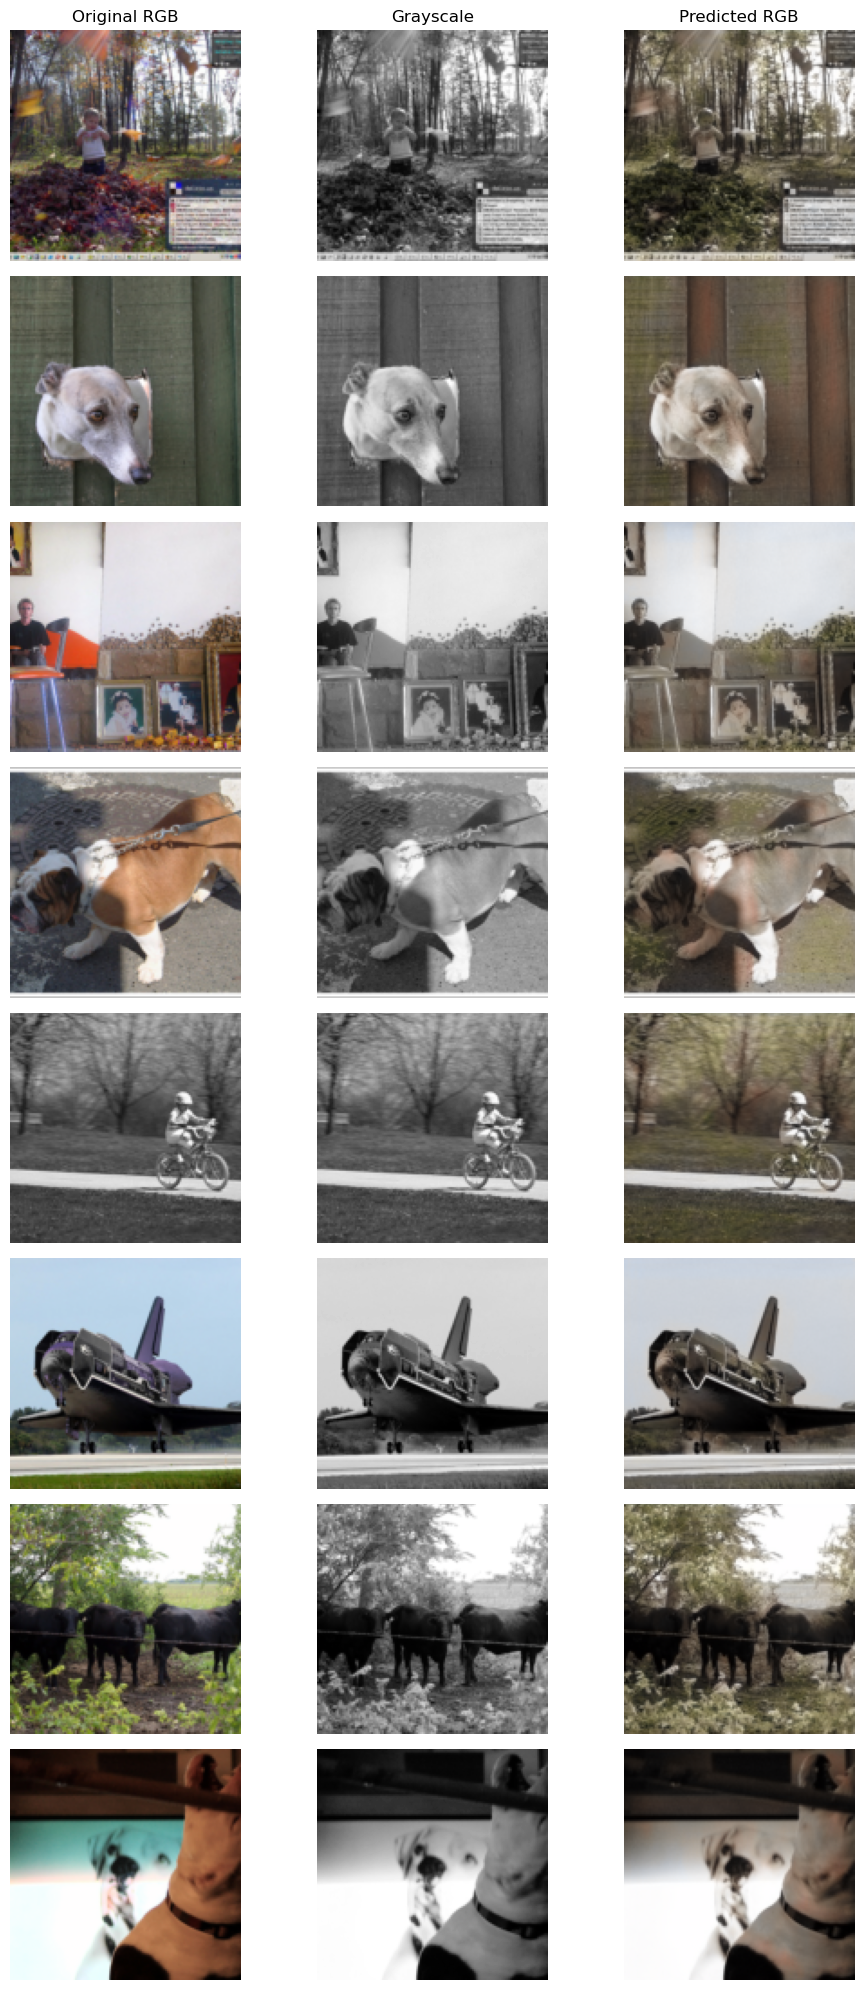

In [ ]:
n_show = 8

fig, axes = plt.subplots(n_show, 3, figsize=(10, n_show * 2.5))

for i in range(n_show):
    axes[i, 0].imshow(rgb_images[i]["true_rgb"])
    axes[i, 1].imshow(samples[i]["L"], cmap="gray", vmin=0, vmax=1)
    axes[i, 2].imshow(rgb_images[i]["pred_rgb"])

    for ax in axes[i]:
        ax.axis("off")

axes[0, 0].set_title("Original RGB")
axes[0, 1].set_title("Grayscale")
axes[0, 2].set_title("Predicted RGB")

plt.tight_layout()
plt.show()

In [ ]:
for group, x in [("True", ab), ("Pred", pred_ab)]:
    print(group)
    print("Mean a:", x[:, 0].mean().item())
    print("Mean b:", x[:, 1].mean().item())
    print("Mean |a|:", x[:, 0].abs().mean().item())
    print("Mean |b|:", x[:, 1].abs().mean().item())
    print()

True
Mean a: 0.014557400718331337
Mean b: 0.015374312177300453
Mean |a|: 0.04467958211898804
Mean |b|: 0.08364629745483398

Pred
Mean a: 0.008090514689683914
Mean b: 0.0351458378136158
Mean |a|: 0.011448444798588753
Mean |b|: 0.04848781228065491



In [ ]:
gray_ab = torch.zeros_like(ab)

print("Gray baseline L1:", criterion(gray_ab, ab).item())
print("UNet L1:", criterion(pred_ab, ab).item())

Gray baseline L1: 0.06416293978691101
UNet L1: 0.06258974969387054


### Выводы

После 20 эпох обучения U-Net предсказывает преимущественно тусклые, близкие к серым цвета. Модель частично восстанавливает характерные оттенки неба, кожи и некоторых объектов, но плохо справляется с насыщенными цветами, особенно с одеждой и другими объектами, цвет которых может сильно различаться.

На исследованном батче из 32 изображений:

- Среднее абсолютное значение канала `a` у предсказаний примерно в 3.9 раза меньше, чем у оригиналов.
- Для канала `b` аналогичное значение меньше примерно в 1.7 раза.
- L1 Loss модели составил **0.06259**, тогда как полностью серое предсказание (`a = b = 0`) получило **0.06416**.

Таким образом, на данном батче U-Net уменьшила L1 Loss относительно серого baseline всего на **2.45%**.

Одна из возможных причин низкой насыщенности — использование L1 Loss. При такой функции потерь модели может быть выгоднее предсказывать нейтральные оттенки для объектов, цвет которых неоднозначен.

Также стоит отметить, что нормализованные значения `ab` сами по себе в среднем достаточно малы по модулю. Поэтому даже при предсказании нулевых значений разница с настоящими цветами по L1 получается небольшой. Это объясняет, почему полностью серое изображение получило такой низкий Loss.

Помимо функции потерь, на результат могут влиять ограничения архитектуры, в частности encoder, и недостаточное обучение.

Полученные результаты показывают, что **низкий L1 Loss не гарантирует хорошего визуального качества колоризации** 